In [1]:
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import GRU, Dense
import time

In [2]:
!pip install yfinance scikit-learn

In [3]:
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, Dense

In [4]:
df = yf.download('RELIANCE.NS', period='2y')
df = df[['Open','High','Low','Close','Volume']]
df = df.dropna()
print(df.head())

[*********************100%***********************]  1 of 1 completed

Price              Open         High          Low        Close      Volume
Ticker      RELIANCE.NS  RELIANCE.NS  RELIANCE.NS  RELIANCE.NS RELIANCE.NS
Date                                                                      
2024-11-05  1281.929288  1298.337635  1275.137962  1294.124023    16267479
2024-11-06  1298.783770  1316.927134  1289.067630  1314.002319    21625209
2024-11-07  1312.663933  1312.663933  1291.447135  1294.471069     9611974
2024-11-08  1286.539434  1290.505186  1264.083341  1272.758423    19814406
2024-11-11  1267.999465  1274.989151  1256.151831  1261.802979     9056552


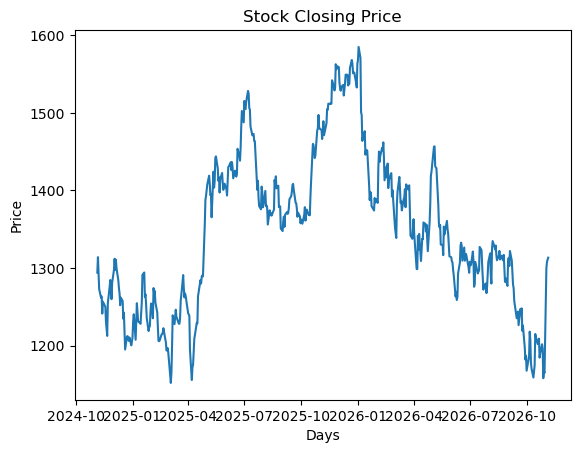

In [5]:
plt.plot(df['Close'])
plt.title('Stock Closing Price')
plt.xlabel('Days')
plt.ylabel('Price')
plt.show()

In [6]:
scaler = MinMaxScaler()
scaled = scaler.fit_transform(df)

In [7]:
X,y = [],[]
for i in range(30,len(scaled)):
    X.append(scaled[i-30:i])
    y.append(scaled[i,3])

X,y = np.array(X),np.array(y)

In [8]:
split = int(0.8*len(X))
X_train,X_test = X[:split],X[split:]
y_train,y_test = y[:split],y[split:]

X_train,X_val = X_train[:int(.8*len(X_train))],X_train[int(.8*len(X_train)):]
y_train,y_val = y_train[:int(.8*len(y_train))],y_train[int(.8*len(y_train)):]

In [15]:
rnn = Sequential([tf.keras.Input((30,5)),SimpleRNN(50),Dense(1)])
gru = Sequential([tf.keras.Input((30,5)),GRU(50),Dense(1)])

rnn.compile(optimizer='adam',loss='mse')
gru.compile(optimizer='adam',loss='mse')

In [16]:
t = time.time()
h1 = rnn.fit(X_train,y_train,epochs=3,batch_size=32,validation_data=(X_val,y_val))
rnn_time = time.time()-t

Epoch 1/3
10/10 ━━━━━━━━━━━━━━━━━━━━ 4s 95ms/step - loss: 0.3034 - val_loss: 0.0935
Epoch 2/3
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - loss: 0.0429 - val_loss: 0.0103
Epoch 3/3
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - loss: 0.0121 - val_loss: 0.0171


In [17]:
t = time.time()
h2 = gru.fit(X_train,y_train,epochs=3,batch_size=32,validation_data=(X_val,y_val))
gru_time = time.time()-t

Epoch 1/3
10/10 ━━━━━━━━━━━━━━━━━━━━ 5s 115ms/step - loss: 0.3088 - val_loss: 0.0159
Epoch 2/3
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step - loss: 0.0278 - val_loss: 0.0602
Epoch 3/3
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step - loss: 0.0301 - val_loss: 0.0189


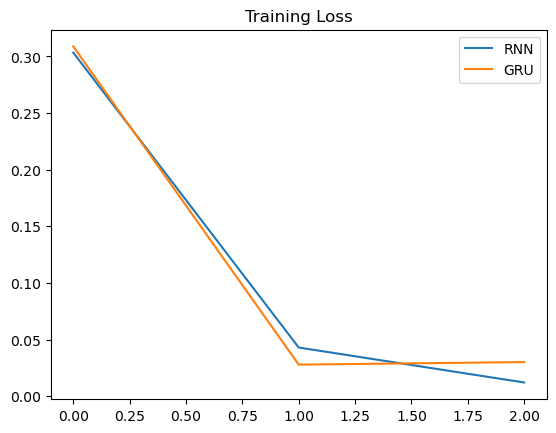

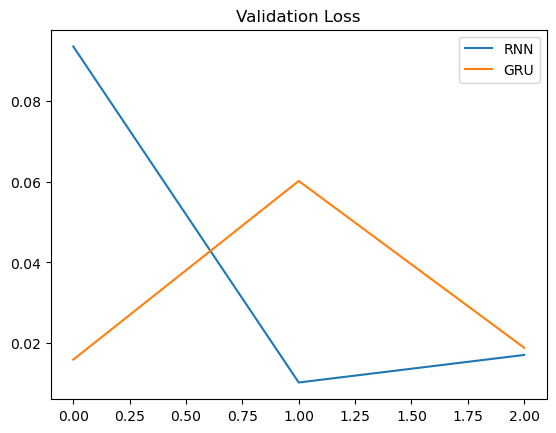

In [18]:
plt.plot(h1.history['loss'],label='RNN')
plt.plot(h2.history['loss'],label='GRU')
plt.title('Training Loss')
plt.legend()
plt.show()

plt.plot(h1.history['val_loss'],label='RNN')
plt.plot(h2.history['val_loss'],label='GRU')
plt.title('Validation Loss')
plt.legend()
plt.show()

In [19]:
rnn_loss = rnn.evaluate(X_test,y_test,verbose=0)
gru_loss = gru.evaluate(X_test,y_test,verbose=0)

print("RNN Test Loss:",rnn_loss)
print("GRU Test Loss:",gru_loss)
print("RNN Time:",rnn_time)
print("GRU Time:",gru_time)

RNN Test Loss: 0.01466402318328619
GRU Test Loss: 0.027345171198248863
RNN Time: 4.587280035018921
GRU Time: 6.416677474975586


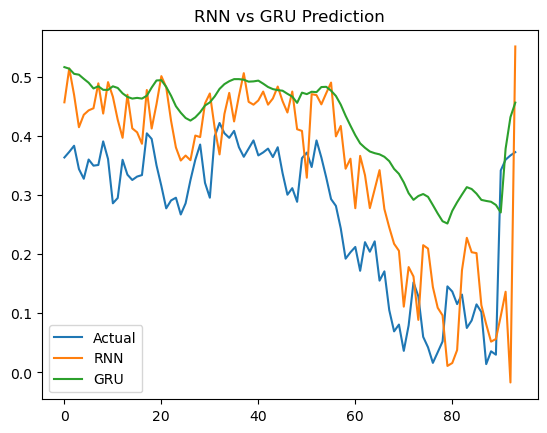

In [20]:
p1 = rnn.predict(X_test,verbose=0)
p2 = gru.predict(X_test,verbose=0)

plt.plot(y_test,label='Actual')
plt.plot(p1,label='RNN')
plt.plot(p2,label='GRU')
plt.title('RNN vs GRU Prediction')
plt.legend()
plt.show()